### Inlämningsuppgift - analys av Hälsostudie
*Kurs: Pythonprogrammering och statistisk dataanalys*

***

## 1. Datainläsning och översikt
I detta avsnitt läses datasetet in och granskas för att kontrollera datatyper, eventuella saknade värden och grundläggande struktur. Här definieras även medicinska normalvärden för de hälsomarkörer som ingår i analysen.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


data = pd.read_csv("data/health_study_dataset.csv")

In [2]:
# add a column for bmi, that is a better indicator of health risks than body weight alone
data["bmi"] = (data["weight"] / (data["height"] / 100) ** 2).round(2)
data = data[["id", "age", "sex", "weight", "height", "bmi", "systolic_bp", "cholesterol", "smoker", "disease"]]

In [3]:
display(data.sample(8))
display(data.info())
display(data.describe())
display(data.describe(include = ['str']))

,id,age,sex,weight,height,bmi,systolic_bp,cholesterol,smoker,disease
98,99,50,F,56.3,164.8,20.73,137.3,5.51,No,0
778,779,48,M,91.7,174.1,30.25,152.8,4.07,No,1
531,532,25,F,77.6,162.7,29.31,127.5,4.72,No,0
169,170,38,M,69.4,171.7,23.54,147.0,4.18,Yes,0
579,580,67,F,43.9,175.2,14.30,156.6,5.92,Yes,0
109,110,48,M,70.0,173.4,23.28,144.2,4.50,No,0
528,529,53,M,69.8,174.9,22.82,151.3,5.21,No,0
717,718,52,F,74.7,169.7,25.94,145.8,5.59,No,1


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   weight       800 non-null    float64
 4   height       800 non-null    float64
 5   bmi          800 non-null    float64
 6   systolic_bp  800 non-null    float64
 7   cholesterol  800 non-null    float64
 8   smoker       800 non-null    str    
 9   disease      800 non-null    int64  
dtypes: float64(5), int64(3), str(2)
memory usage: 62.6 KB


None

,id,age,weight,height,bmi,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,73.413000,171.849250,24.933612,149.178625,4.929150,0.058750
std,231.0844,14.501118,13.685059,9.804259,4.661216,12.793360,0.848413,0.235303
min,1.0000,18.000000,33.700000,144.400000,12.630000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,64.800000,164.775000,21.917500,140.900000,4.327500,0.000000
50%,400.5000,50.000000,73.200000,171.350000,24.700000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,82.600000,178.925000,28.012500,157.600000,5.482500,0.000000
max,800.0000,90.000000,114.400000,200.400000,40.140000,185.900000,7.880000,1.000000


,sex,smoker
count,800,800
unique,2,2
top,F,No
freq,403,587


In [4]:
dup_rows = data.duplicated().sum()

if dup_rows > 0:
    data = data.drop_duplicates()
    print(f"{dup_rows} row(s) removed due to duplicates.")
else:
    print("There are no duplicate rows in the dataset.")

There are no duplicate rows in the dataset.


In [5]:
#print(data[['weight', 'bmi', 'sex', 'age', 'height']].sort_values(by='weight').head(20))

In [6]:
#print(data[['height', 'sex', 'age', 'weight']].sort_values(by='height').head(20))

In [7]:
reference_target_value = pd.DataFrame({
    "Mätvärde": [
        "--------------------",
        "Systoliskt blodtryck", "Systoliskt blodtryck", "Systoliskt blodtryck", "--------------------",
        "Totalkolesterol", "LDL-kolesterol",
        "HDL-kolesterol", "HDL-kolesterol", "--------------------",
        "BMI", "BMI", "BMI", "BMI"
    ],
    "Nivå": [
        "--------------",
        "Optimalt", "Normalt", "Förhöjt", "--------------",
        "Önskvärt", "Önskvärt",
        "Önskvärt (M)", "Önskvärt (K)", "--------------",
        "Undervikt", "Normalvikt", "Övervikt", "Obesitas"
    ],
    "Gränsvärde": [
        "-------------",
        "under 120", "120 – 140", "över 140", "-------------",
        "under 5,0", "under 3,0",
        "över 1,0", "över 1,2", "-------------",
        "under 18,5", "18,5 – 24,9", "25,0 – 29,9", "över 30,0"
    ],
    "Enhet": [
        "-------",
        "mmHg", "mmHg", "mmHg", "-------",
        "mmol/l", "mmol/l",
        "mmol/l", "mmol/l", "-------",
        "kg/m2", "kg/m2", "kg/m2", "kg/m2"
    ]
})

print("Referens- och riktvärden\n")
print(reference_target_value.to_string(index=False))
print("\nKälla: https://www.1177.se\n")

Referens- och riktvärden

            Mätvärde           Nivå    Gränsvärde   Enhet
-------------------- -------------- ------------- -------
Systoliskt blodtryck       Optimalt     under 120    mmHg
Systoliskt blodtryck        Normalt     120 – 140    mmHg
Systoliskt blodtryck        Förhöjt      över 140    mmHg
-------------------- -------------- ------------- -------
     Totalkolesterol       Önskvärt     under 5,0  mmol/l
      LDL-kolesterol       Önskvärt     under 3,0  mmol/l
      HDL-kolesterol   Önskvärt (M)      över 1,0  mmol/l
      HDL-kolesterol   Önskvärt (K)      över 1,2  mmol/l
-------------------- -------------- ------------- -------
                 BMI      Undervikt    under 18,5   kg/m2
                 BMI     Normalvikt   18,5 – 24,9   kg/m2
                 BMI       Övervikt   25,0 – 29,9   kg/m2
                 BMI       Obesitas     över 30,0   kg/m2

Källa: https://www.1177.se



### 📊 Observationer från datautforskningen

#### Datasetets struktur
* **Storlek:** 800 rader och 10 kolumner *(varav 1 är skapad/tillagd)*
* **Datakvalitet:** Inga saknade värden (`NaN`) och inga dubbletter

#### Datatyper
* **Numeriska:** `age`, `height`, `weight`, `bmi`, `systolic_bp`, `cholesterol`
* **Kategoriska:** `sex`, `smoker`, `disease` *(kodad)*
* **Identifierare:** `id`

#### Variationsvidd och fördelning
* **Ålder:** Varierar mellan **18 och 90 år**
* **Könsfördelning:** Jämn fördelning mellan kvinnor och män
* **Blodtryck:** En stor andel av deltagarna har förhöjt systoliskt blodtryck
* **Rökare:** Cirka **25 %** av deltagarna i studien är rökare
* **Sjukdom (`disease`):** Cirka **6 %** har en odefinierad sjukdom

---

#### 💡 Funderingar & antaganden

* **Avvikande värden i vikt och längd:** 
  Är alla värden för vikt och längd korrekta? Det finns deltagare med låg vikt som sticker ut något i fördelningen och bör dubbelkollas mot beräknat `bmi`.
* **Definition av kolesterol:** 
  Det framgår inte av datasetet vilken typ av kolesterol som avses:
  * **HDL:** Det "goda" kolesterolet
  * **LDL:** Det "onda" kolesterolet
  * **Totalkolesterol:** Sammanlagt kolesterolvärde *(HDL + LDL m.m.)*
  
  > **Antagande:** I den fortsatta analysen antas `cholesterol` avse **totalkolesterol**.

## 2. Deskriptiv statistik och visualisering
Här sammanfattas datasetets centrala variabler med hjälp av central- och spridningsmått (medelvärde, median, min och max). Dessutom visualiseras fördelningar och samband mellan variablerna med olika typer av diagram.

In [8]:
columns_to_analyze = ["age", "weight", "height", "systolic_bp", "cholesterol"]
desc_stats = data[columns_to_analyze].agg(["mean", "median", "min", "max"]).round(2).T
desc_stats.columns = ["medel", "median", "minimum", "maximum"]

display(desc_stats)

,medel,median,minimum,maximum
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


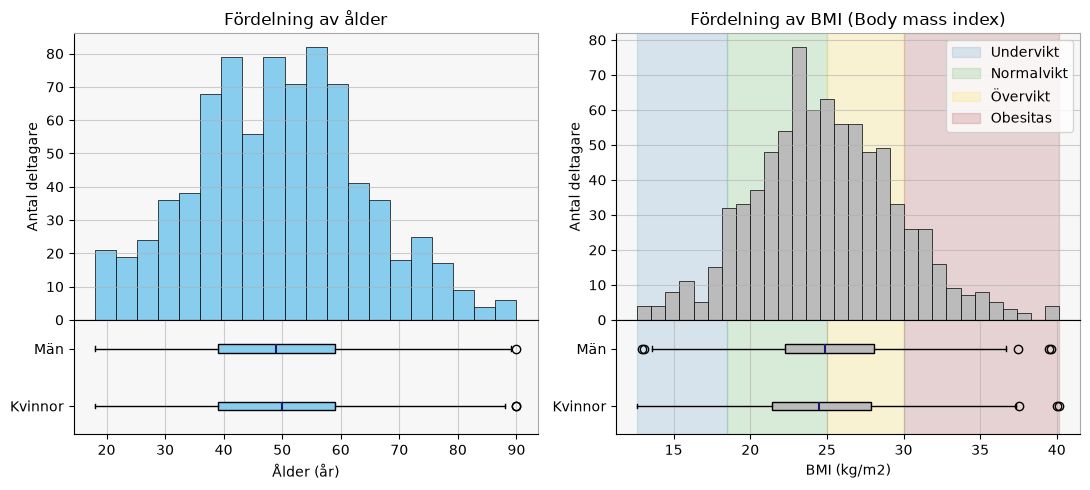

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5), gridspec_kw={"height_ratios":[5,2], 'hspace': 0})

# age
axes[0,0].hist(data.age, bins=20, color='#88CCEE', edgecolor='black', linewidth=0.5)
axes[0,0].set_facecolor("#F7F7F7")
axes[0,0].set_title("Fördelning av ålder")
axes[0,0].set_xlabel("Ålder (år)")
axes[0,0].set_ylabel("Antal deltagare")
axes[0,0].grid(True, axis="y", alpha=0.6)


axes[1,0].boxplot([data.loc[data.sex == "F", "age"], 
                data.loc[data.sex == "M", "age"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                boxprops=dict(facecolor='#88CCEE', edgecolor='black'),
                medianprops = dict(color="midnightblue", linewidth=1.5),
                orientation='horizontal')
axes[1,0].set_facecolor("#F7F7F7")
axes[1,0].set_xlabel("Ålder (år)")
axes[1,0].grid(True, axis="x", alpha=0.6)


# bmi
bmi_min = min(data["bmi"].min(), 15.0)
bmi_max = max(data["bmi"].max(), 35.0)
bmi_zon = [
    {"min": bmi_min, "max": 18.5,    "color": "tab:blue",  "label": "Undervikt"},
    {"min": 18.5,    "max": 25.0,    "color": "tab:green", "label": "Normalvikt"},
    {"min": 25.0,    "max": 30.0,    "color": "gold",      "label": "Övervikt"},
    {"min": 30.0,    "max": bmi_max, "color": "darkred",   "label": "Obesitas"},
]

for zon in bmi_zon:
    axes[0,1].axvspan(zon["min"], zon["max"], color=zon["color"], alpha=0.15, label=zon["label"])
    axes[1,1].axvspan(zon["min"], zon["max"], color=zon["color"], alpha=0.15, label=zon["label"])

axes[0,1].hist(data.bmi, bins=30, color='#BBBBBB', edgecolor='black', linewidth=0.5)
axes[0,1].set_facecolor("#F7F7F7")
axes[0,1].set_title("Fördelning av BMI (Body mass index)")
axes[0,1].set_xlabel("BMI (kg/m2)")
axes[0,1].set_ylabel("Antal deltagare")
axes[0,1].grid(True, axis="y", alpha=0.6)
axes[0,1].legend()

axes[1,1].boxplot([data.loc[data.sex == "F", "bmi"], 
                data.loc[data.sex == "M", "bmi"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                boxprops=dict(facecolor='#BBBBBB', edgecolor='black'),
                medianprops = dict(color="midnightblue", linewidth=1.5),
                orientation='horizontal')
axes[1,1].set_facecolor("#F7F7F7")
axes[1,1].set_xlabel("BMI (kg/m2)")
axes[1,1].grid(True, axis="x", alpha=0.6)


axes[0,0].spines['top'].set_color('darkgray')
axes[0,0].spines['right'].set_color('darkgray')
axes[1,0].spines['right'].set_color('darkgray')
axes[0,1].spines['top'].set_color('darkgray')
axes[0,1].spines['right'].set_color('darkgray')
axes[1,1].spines['right'].set_color('darkgray')

plt.tight_layout()

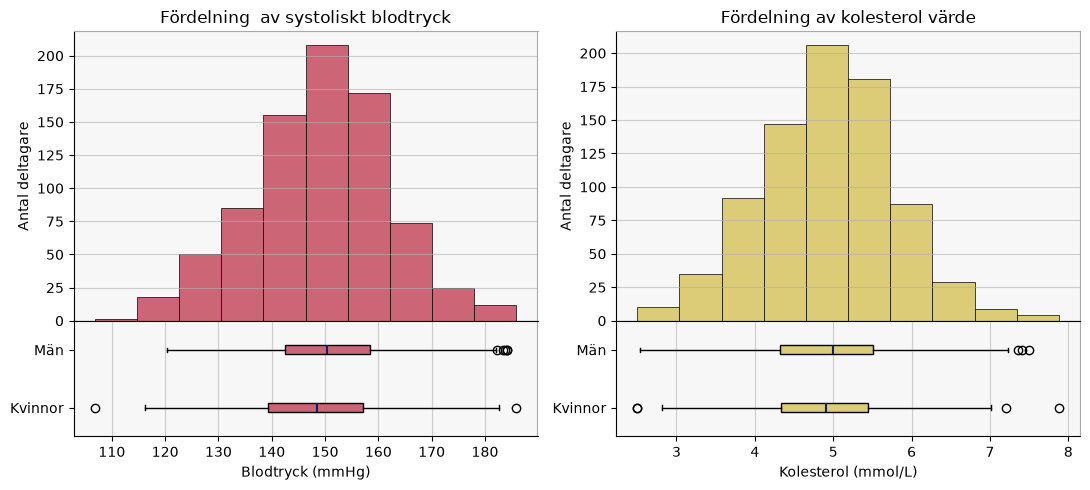

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5), gridspec_kw={"height_ratios":[5,2], 'hspace': 0})

# systolic_bp
axes[0,0].hist(data.systolic_bp, bins=10, color='#CC6677', edgecolor='black', linewidth=0.5)
axes[0,0].set_facecolor("#F7F7F7")
axes[0,0].set_title("Fördelning  av systoliskt blodtryck")
axes[0,0].set_xlabel("Blodtryck (mmHg)")
axes[0,0].set_ylabel("Antal deltagare")
axes[0,0].grid(True, axis="y", alpha=0.6)

axes[1,0].boxplot([data.loc[data.sex == "F", "systolic_bp"], 
                data.loc[data.sex == "M", "systolic_bp"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                boxprops=dict(facecolor='#CC6677', edgecolor='black'),
                medianprops = dict(color="midnightblue", linewidth=1.5),
                orientation='horizontal')
axes[1,0].set_facecolor("#F7F7F7")
axes[1,0].set_xlabel("Blodtryck (mmHg)")
axes[1,0].grid(True, axis="x", alpha=0.6)


# cholesterol
axes[0,1].hist(data.cholesterol, bins=10, color='#DDCC77', edgecolor='black', linewidth=0.5)
axes[0,1].set_facecolor("#F7F7F7")
axes[0,1].set_title("Fördelning av kolesterol värde")
axes[0,1].set_xlabel("Kolesterol (mmol/L)")
axes[0,1].set_ylabel("Antal deltagare")
axes[0,1].grid(True, axis="y", alpha=0.6)

axes[1,1].boxplot([data.loc[data.sex == "F", "cholesterol"], 
                data.loc[data.sex == "M", "cholesterol"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                boxprops=dict(facecolor='#DDCC77', edgecolor='black'),
                medianprops = dict(color="midnightblue", linewidth=1.5),
                orientation='horizontal')
axes[1,1].set_facecolor("#F7F7F7")
axes[1,1].set_xlabel("Kolesterol (mmol/L)")
axes[1,1].grid(True, axis="x", alpha=0.6)


axes[0,0].spines['top'].set_color('darkgray')
axes[0,0].spines['right'].set_color('darkgray')
axes[1,0].spines['right'].set_color('darkgray')
axes[0,1].spines['top'].set_color('darkgray')
axes[0,1].spines['right'].set_color('darkgray')
axes[1,1].spines['right'].set_color('darkgray')

plt.tight_layout()

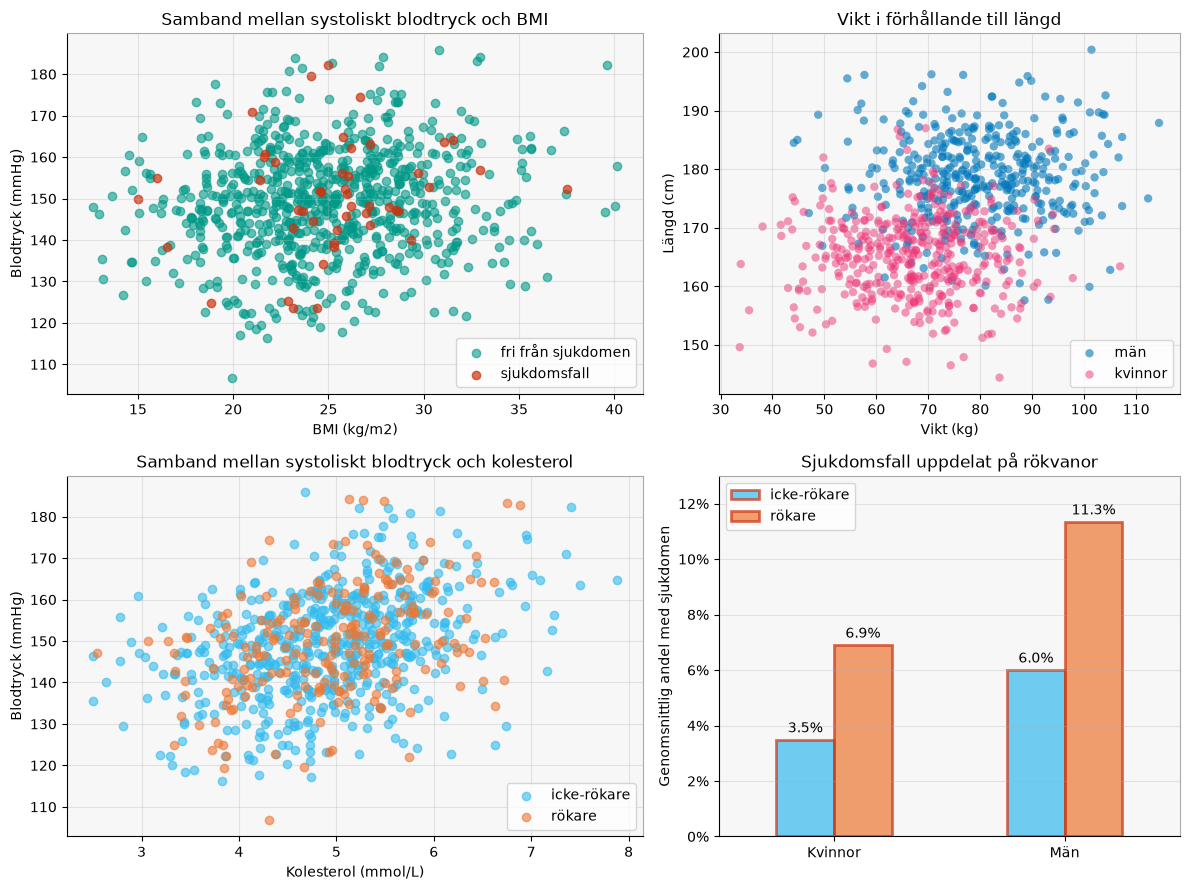

In [15]:
fig2, axes = plt.subplots(2, 2, figsize=(12, 9), gridspec_kw={"width_ratios":[5,4]})

disease_n = data[data['disease'] == 0]
disease_y = data[data['disease'] == 1]

axes[0,0].scatter(disease_n['bmi'], disease_n['systolic_bp'], color='#009988', label='fri från sjukdomen', alpha=0.6)
axes[0,0].scatter(disease_y['bmi'], disease_y['systolic_bp'], color='#CC3311', label='sjukdomsfall', alpha=0.7)
axes[0,0].set_facecolor("#F7F7F7")
axes[0,0].set_title('Samband mellan systoliskt blodtryck och BMI')
axes[0,0].set_xlabel('BMI (kg/m2)')
axes[0,0].set_ylabel('Blodtryck (mmHg)')
axes[0,0].legend(loc="lower right")
axes[0,0].grid(True, alpha=0.3)


m = data[data["sex"] == "M"]
f = data[data["sex"] == "F"]

axes[0,1].scatter(m['weight'], m['height'], color="#0077BB", label='män', alpha=0.6, edgecolors='none')
axes[0,1].scatter(f['weight'], f['height'], color="#EE3377", label='kvinnor', alpha=0.5, edgecolors='none')
axes[0,1].set_facecolor("#F7F7F7")
axes[0,1].set_title('Vikt i förhållande till längd')
axes[0,1].set_xlabel('Vikt (kg)')
axes[0,1].set_ylabel('Längd (cm)')
axes[0,1].legend(loc="lower right")
axes[0,1].grid(True, alpha=0.3)


smoker_n = data[data["smoker"] == "No"]
smoker_y = data[data["smoker"] == "Yes"]

axes[1,0].scatter(smoker_n["cholesterol"], smoker_n["systolic_bp"], color="#33BBEE", label='icke-rökare', alpha=0.6)
axes[1,0].scatter(smoker_y["cholesterol"], smoker_y["systolic_bp"], color="#EE7733", label='rökare', alpha=0.6)
axes[1,0].set_facecolor("#F7F7F7")
axes[1,0].set_title('Samband mellan systoliskt blodtryck och kolesterol')
axes[1,0].set_xlabel("Kolesterol (mmol/L)")
axes[1,0].set_ylabel("Blodtryck (mmHg)")
axes[1,0].legend(loc="lower right")
axes[1,0].grid(True, alpha=0.3)


import matplotlib.ticker as mtick
grouped = data.groupby(['sex', 'smoker'])['disease'].mean().unstack()*100
grouped = grouped.rename(index={'F': 'Kvinnor', 'M': 'Män'}, 
                         columns={'No': 'icke-rökare', 'Yes': 'rökare'})
grouped.plot(kind='bar', ax=axes[1, 1], color=['#33BBEE', '#EE7733'], alpha=0.7, edgecolor='#CC3311', linewidth=2)
axes[1,1].set_facecolor("#F7F7F7")
axes[1,1].set_ylim(top=13)
axes[1,1].set_title('Sjukdomsfall uppdelat på rökvanor')
axes[1,1].set_xlabel('')
axes[1,1].set_ylabel('Genomsnittlig andel med sjukdomen')
axes[1,1].tick_params(axis='x', rotation=0)
axes[1,1].legend(title='')
axes[1,1].grid(True, axis="y", alpha=0.3)
axes[1,1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for container in axes[1, 1].containers:
    axes[1,1].bar_label(container, fmt='%.1f%%', padding=3)


axes[0,0].spines['top'].set_color('darkgray')
axes[0,0].spines['right'].set_color('darkgray')
axes[1,0].spines['top'].set_color('darkgray')
axes[1,0].spines['right'].set_color('darkgray')
axes[0,1].spines['top'].set_color('darkgray')
axes[0,1].spines['right'].set_color('darkgray')
axes[1,1].spines['top'].set_color('darkgray')
axes[1,1].spines['right'].set_color('darkgray')

plt.tight_layout()

### 📊 Observationer från dataanalysen

#### 1. Fördelning av enskilda variabler
* **Ålder:** Ungefär symmetrisk (klockformad) fördelning kring **50 år**, med liknande spridning hos både män och kvinnor.
* **BMI:** Majoriteten av deltagarna ligger inom spannet för normalvikt och övervikt, med tämligen liknande spridning mellan könen.
* **Blodtryck:** Koncentrerat kring **145–155 mmHg**, med några enstaka extremvärden (*outliers*).
* **Kolesterol:** Koncentrerat kring **5 mmol/L** med liknande medianer och spridning mellan män och kvinnor.

#### 2. Samband mellan variabler
* **Vikt mot längd *(efter kön)*:** En förväntad positiv korrelation där längre personer generellt väger mer. Diagrammet visar också en tydlig uppdelning där män i genomsnitt är längre och tyngre än kvinnor.
* **BMI mot blodtryck *(efter sjukdom)*:** Inget tydligt samband mellan högre BMI och högre blodtryck. Sjukdomsfallen är utspridda över hela fältet, vilket tyder på att varken BMI eller blodtryck ensamt förklarar sjukdomen.
* **Blodtryck mot kolesterol *(efter rökvanor)*:** En svag positiv trend där högre kolesterolvärde tenderar att sammanfalla med något högre blodtryck. Rökare och icke-rökare är dock jämnt fördelade över skalan, vilket innebär att rökning inte verkar driva upp kolesterolet eller blodtrycket markant i denna studie.

#### 3. Sjukdomsförekomst & riskfaktorer
* **Sjukdomsfall *(uppdelat på rökvanor)*:** Andelen med sjukdomen är **nästan dubbelt så hög bland rökare** jämfört med icke-rökare. Män har dessutom generellt en högre sjukdomsförekomst än kvinnor.


## 3. Slumpbaserad simulering av sjukdomsförekomst
Utifrån den observerade andelen individer med **sjukdomen** i datasetet simuleras ett nytt stickprov om 1 000 individer med hjälp av NumPy. Syftet är att jämföra utfallet från en teoretisk sannolikhetsmodell med den faktiska datan.

In [12]:
actual_disease_rate = data["disease"].mean()

rng = np.random.default_rng(42)

simulated_outcome = rng.binomial(n=1, p=actual_disease_rate, size=1000)
simulated_disease_rate = simulated_outcome.mean()

print(f"Andel med sjukdomen (dataset):         {actual_disease_rate:.3%}")
print(f"Sannolikhet för sjukdom (simulering):  {simulated_disease_rate:.3%}")
print(f"Skillnad:                              {abs(actual_disease_rate - simulated_disease_rate)*100:.3}")

Andel med sjukdomen (dataset):         5.875%
Sannolikhet för sjukdom (simulering):  5.400%
Skillnad:                              0.475


> ### 📊 Resultat
> * **Simulerat utfall:** 1 000 iterationer stämmer väl överens med datasetets verkliga sjukdomsfrekvens (**5,875 %**).
> * **Avvikelse:** Liten slumpmässig avvikelse på **0,475 procentenheter**.
> * **Reproducerbarhet:** Genom att använda `np.random.default_rng(seed=42)` säkerställs exakt samma resultat vid varje körning.


## 4. Skattning med konfidensintervall
Här beräknas ett 95-procentigt konfidensintervall för det genomsnittliga **systoliska blodtrycket** med två olika metoder: normalapproximation och bootstrap. Resultaten jämförs för att bedöma osäkerheten i skattningen.

In [13]:
x = data["systolic_bp"]
mean = x.mean()

print(f"Medelvärde blodtryck: {mean:.2f} mmHg")


# 95% confidence interval with normal approximation
n = x.size
sd = x.std(ddof=1)
se = sd / np.sqrt(n) #standard error
z = 1.96
ci_norm = (mean - z * se, mean + z * se)

print(f"\n95% KI med normalapproximation: [{ci_norm[0]:.2f}, {ci_norm[1]:.2f}]")


# 95% confidence interval with bootstrap
rng = np.random.default_rng(42)
n_boot = 10000
bootstrap_means = []

for i in range(n_boot):
    sample = rng.choice(x, size=n, replace=True)
    bootstrap_means.append(sample.mean())

ci_boot = np.percentile(bootstrap_means, [2.5, 97.5])

print(f"\n95% KI med bootstrap ({n_boot} omsamplingar): [{ci_boot[0]:.2f}, {ci_boot[1]:.2f}]")

Medelvärde blodtryck: 149.18 mmHg

95% KI med normalapproximation: [148.29, 150.07]

95% KI med bootstrap (10000 omsamplingar): [148.31, 150.05]


### ⚖️ Jämförelse av metoder

> **Slutsats:** Metoderna ger nästintill identiska intervall (skillnad på hundradels mmHg), vilket saknar klinisk betydelse och visar att samplingsfördelningen är normalfördelad. **Normalapproximation är därför fullt tillräcklig.**

* **Välj normalapproximation** vid stora stickprov eller normalfördelad grunddata (bygger på centrala gränsvärdessatsen).
* **Välj bootstrap** vid snedfördelad data, små stickprov eller andra skattningar än medelvärdet, då den bättre fångar datans verkliga form.


## 5. Hypotesprövning och statistisk styrka (power)
I detta avsnitt testas hypotesen om huruvida **rökare har ett högre genomsnittligt blodtryck än icke-rökare**. Slutligen genomförs en simulering för att utvärdera testets **statistiska styrka (power)**, det vill säga sannolikheten att upptäcka en verklig skillnad.

In [14]:
# Welch's t-test
# --------------
# H0: mu_smoker <= mu_non_smoker
# H1: mu_smoker > mu_non_smoker
smoker_bp = data[data['smoker'] == 'Yes']['systolic_bp']
non_smoker_bp = data[data['smoker'] == 'No']['systolic_bp']

t_stat, p_val = stats.ttest_ind(smoker_bp, non_smoker_bp, equal_var=False, alternative='greater')

print(f"\nMedelvärde blodtryck, rökare:      {smoker_bp.mean():.2f} mmHg")
print(f"Medelvärde blodtryck, icke-rökare: {non_smoker_bp.mean():.2f} mmHg")
print(f"\nt-värde: {t_stat:.2f} p-värde: {p_val:.3f}")


# Power analysis
# --------------
n_smok = len(smoker_bp)
n_non_smok = len(non_smoker_bp)
mu_smok, std_smok = smoker_bp.mean(), smoker_bp.std()
mu_non_smok, std_non_smok = non_smoker_bp.mean(), non_smoker_bp.std()

# Simulation 1000 tests
rng = np.random.default_rng(42)
n_sim = 1000
significant_count = 0

for _ in range(n_sim):
    # create simulerad data
    sim_smok = rng.normal(loc=mu_smok, scale=std_smok, size=n_smok)
    sim_non_smok = rng.normal(loc=mu_non_smok, scale=std_non_smok, size=n_non_smok)
    # perform the test
    _, p = stats.ttest_ind(sim_smok, sim_non_smok, equal_var=False, alternative='greater')
    if p < 0.05:
        significant_count += 1

power = significant_count / n_sim
print(f"\nBeräknad statistisk styrka (Power): {power:.4f} ({power*100:.1f}%)")


Medelvärde blodtryck, rökare:      149.52 mmHg
Medelvärde blodtryck, icke-rökare: 149.05 mmHg

t-värde: 0.45 p-värde: 0.326

Beräknad statistisk styrka (Power): 0.1020 (10.2%)


### 📊 Resultat

#### 🧪 Metod & Hypoteser
För att jämföra blodtrycket mellan grupperna använder vi **Welch’s t-test**, eftersom rökare och icke-rökare kan ha olika gruppstorlek och varians. Vi genomför ett **ensidigt test** på signifikansnivån $\alpha = 0{,}05$:

* **Nollhypotes ($H_0$):** $\mu_{\text{rökare}} \le \mu_{\text{icke-rökare}}$ *(rökare har inte högre medelblodtryck)*
* **Alternativhypotes ($H_1$):** $\mu_{\text{rökare}} > \mu_{\text{icke-rökare}}$ *(rökare har högre medelblodtryck)*

#### 📌 Utfall av t-test
Testet gav följande resultat:
* **t-värde:** `0,45`
* **p-värde:** `0,326`

Eftersom det erhållna $p$-värdet är större än signifikansnivån ($\alpha = 0{,}05$) **kan vi inte förkasta nollhypotesen**. Det innebär att vi utifrån detta dataset inte kan säkerställa att rökare har högre medelblodtryck än icke-rökare.

---

#### ⚡ Power-analys (Statistisk styrka)
För att utvärdera testets tillförlitlighet genomförde vi en simuleringsbaserad power-analys (1 000 iterationer) utifrån den observerade skillnaden i datan:

* **Beräknad power:** `10,2 %` *(sannolikhet att upptäcka en verklig skillnad vid $p < 0{,}05$)*
* **Tolkning:** Den låga statistiska styrkan innebär en **hög risk för typ II-fel** (falskt negativt resultat). Detta beror sannolikt på att stickprovet är för litet i förhållande till den lilla uppmätta skillnaden och spridningen i datan.
